# ****BASELINE MODELING****

Notebook ini membangun fungsi metrik kesalahan dan model-model pembanding, lalu mengukurnya pada data validasi sebagai tolok ukur bagi Algoritma Genetika pada notebook berikutnya.

<p align="center">
    <img src="../xLain_Lain/img/bm_0.png" alt="Baseline Modeling" witdh="100" height="500">
</p>

---

### ****DAFTAR ISI****

0. Persiapan Lingkungan Kerja dan Pemuatan Data Latih dan Validasi
1. Metrik Kesalahan dan Protokol Peramalan Satu Langkah
2. Model Pembanding Sederhana: Naive dan Moving Average
3. Model Pembanding Berbasis Pembelajaran: Regresi Linear dan Perceptron Berlapis
4. Fuzzy Time Series Interval Sama Panjang
5. ARIMA
6. Perbandingan Model dan Implikasinya
7. Ringkasan dan Langkah Berikutnya

### ****0. Persiapan Lingkungan Kerja dan Pemuatan Data Latih dan Validasi****

#### ****0.1 Mengapa langkah ini penting?****

Sesuai rancangan evaluasi, data uji hanya boleh dipakai satu kali untuk pelaporan akhir. Karena itu notebook ini sengaja hanya memuat data latih dan data validasi. Seluruh pemilihan konfigurasi model dasar dilakukan dengan data validasi, sehingga hasil pada data uji nanti benar-benar belum pernah dilihat.

#### ****0.2 Memuat data****

Sel berikut memuat paket dan berkas pembagian data dari Notebook 3, hanya mengambil subset latih dan validasi, lalu menyiapkan harga pencatatan sebelumnya sebagai acuan untuk setiap hari validasi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import config
from src.metrics import mape, rmse, mae, ringkas_metrik

rupiah = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

pembagian = pd.read_csv(config.DIR_CLEAN / "pembagian_data.csv", parse_dates=["tanggal"])
pembagian = pembagian[pembagian["subset"].isin(["latih", "validasi"])]

latih = pembagian[pembagian["subset"] == "latih"].set_index("tanggal")["harga"]
validasi = pembagian[pembagian["subset"] == "validasi"].set_index("tanggal")["harga"]
semua = pd.concat([latih, validasi])
acuan_validasi = semua.shift(1).loc[validasi.index]

print("=" * 62)
print("Data yang dimuat")
print("=" * 62)
print(f"Data latih : {len(latih)} hari ({latih.index.min().date()} sampai {latih.index.max().date()})")
print(f"Data validasi : {len(validasi)} hari ({validasi.index.min().date()} sampai {validasi.index.max().date()})")
print("Data uji : sengaja tidak dimuat pada notebook ini")
print()
print(f"Acuan hari validasi pertama sama dengan harga latih terakhir: "
      f"{acuan_validasi.iloc[0] == latih.iloc[-1]}")

Data yang dimuat
Data latih : 1221 hari (2020-01-02 sampai 2024-11-06)
Data validasi : 261 hari (2024-11-07 sampai 2025-11-06)
Data uji : sengaja tidak dimuat pada notebook ini

Acuan hari validasi pertama sama dengan harga latih terakhir: True


>INTERPRETASI (Pemuatan data)
>
>Data latih berisi 1.221 hari (2 Januari 2020 sampai 6 November 2024) dan data validasi 261 hari (7 November 2024 sampai 6 November 2025), sesuai pembagian pada Notebook 3. Data uji tidak dimuat, sehingga seluruh keputusan pada notebook ini tidak dapat dipengaruhi data uji. Acuan hari validasi pertama sama dengan harga latih terakhir, yang menunjukkan sambungan antara kedua bagian data sudah benar.

### ****1. Metrik Kesalahan dan Protokol Peramalan Satu Langkah****

#### ****1.1 Mengapa langkah ini penting?****

Seluruh model dibandingkan dengan fungsi metrik yang sama dan skema peramalan yang sama. Bila fungsi metrik keliru, seluruh kesimpulan ikut keliru tanpa terlihat. Karena itu fungsi metrik diuji dulu pada contoh kecil yang hasilnya dapat dihitung dengan tangan.

#### ****1.2 Protokol peramalan satu langkah****

Untuk setiap hari pada data validasi, model meramalkan harga hari itu hanya dari harga-harga sebelumnya, dengan harga sebelumnya diambil dari nilai aktual. Model dilatih pada data latih saja dan tidak dilatih ulang selama validasi. Hari validasi pertama memakai harga latih terakhir sebagai acuan.

#### ****1.3 Yang dilakukan****

Sel berikut:
1. Menguji fungsi MAPE, RMSE, dan MAE pada tiga angka yang dapat dihitung dengan tangan.
2. Menampilkan contoh pasangan harga aktual dan harga pencatatan sebelumnya pada lima hari validasi pertama.

In [2]:
a = np.array([100.0, 200.0, 400.0])
p = np.array([110.0, 180.0, 400.0])
assert np.isclose(mape(a, p), 100 * (0.10 + 0.10 + 0.0) / 3)
assert np.isclose(rmse(a, p), np.sqrt((100 + 400 + 0) / 3))
assert np.isclose(mae(a, p), 10.0)
assert np.isclose(mape(a, a), 0.0)

print("=" * 62)
print("Uji fungsi metrik pada contoh kecil")
print("=" * 62)
print("Aktual    :", a.tolist())
print("Prediksi  :", p.tolist())
for nama, nilai in ringkas_metrik(a, p).items():
    print(f"{nama:<8}: {nilai:.4f}")
print("Hasil hitung tangan: MAPE 6.6667, RMSE 12.9099, MAE 10.0000. Semua cocok.")

print()
print("=" * 62)
print("Contoh protokol satu langkah (5 hari validasi pertama)")
print("=" * 62)
contoh = pd.DataFrame({"aktual": validasi.head(5), "harga_pencatatan_sebelumnya": acuan_validasi.head(5)})
print(contoh.to_string())

Uji fungsi metrik pada contoh kecil
Aktual    : [100.0, 200.0, 400.0]
Prediksi  : [110.0, 180.0, 400.0]
MAPE_%  : 6.6667
RMSE    : 12.9099
MAE     : 10.0000
Hasil hitung tangan: MAPE 6.6667, RMSE 12.9099, MAE 10.0000. Semua cocok.

Contoh protokol satu langkah (5 hari validasi pertama)
             aktual  harga_pencatatan_sebelumnya
tanggal                                         
2024-11-07  30650.0                      29350.0
2024-11-08  30450.0                      30650.0
2024-11-11  31500.0                      30450.0
2024-11-12  33350.0                      31500.0
2024-11-13  33700.0                      33350.0


>INTERPRETASI (Uji metrik dan protokol)
>
>Ketiga fungsi metrik menghasilkan angka yang sama dengan hitungan tangan pada contoh kecil (MAPE 6,6667%, RMSE 12,9099, MAE 10,0000), sehingga fungsi tersebut dapat dipercaya untuk membandingkan model.
>
>Contoh protokol menunjukkan cara kerja peramalan satu langkah: untuk setiap hari validasi, harga pencatatan sebelumnya adalah harga aktual (bukan hasil prediksi). Pada lima hari pertama, selisih antara harga sebelumnya dan harga hari itu berkisar dari minus 0,7% sampai 5,9%, misalnya Rp 29.350 menjadi Rp 30.650 pada 7 November 2024. Selisih inilah yang menjadi kesalahan model naive pada hari-hari tersebut.

### ****2. Model Pembanding Sederhana: Naive dan Moving Average****

#### ****2.1 Mengapa langkah ini penting?****

Model sederhana adalah ukuran kejujuran. Bila model yang rumit tidak mampu mengalahkan model yang hanya mengulang harga kemarin, kerumitannya tidak memberi manfaat. Pada Notebook 3 ditemukan autokorelasi harga 0,991, sehingga model naive diperkirakan sangat sulit dikalahkan.

#### ****2.2 Model yang dibangun****

1. Naive: harga hari ini diramalkan sama dengan harga pencatatan sebelumnya.
2. Moving average: harga diramalkan sebagai rata-rata k pencatatan terakhir, dengan k dipilih dari 2, 3, 5, 7, 10, dan 14 berdasarkan MAPE validasi.

In [3]:
hasil_validasi = {}
prediksi = {}

prediksi["Naive"] = acuan_validasi.copy()
hasil_validasi["Naive"] = ringkas_metrik(validasi, prediksi["Naive"])

kandidat_k = [2, 3, 5, 7, 10, 14]
baris = []
for k in kandidat_k:
    ma = semua.rolling(k).mean().shift(1).loc[validasi.index]
    baris.append({"k": k, **ringkas_metrik(validasi, ma)})
tabel_ma = pd.DataFrame(baris).set_index("k")
k_terbaik = int(tabel_ma["MAPE_%"].idxmin())

nama_ma = f"Moving average (k={k_terbaik})"
prediksi[nama_ma] = semua.rolling(k_terbaik).mean().shift(1).loc[validasi.index]
hasil_validasi[nama_ma] = ringkas_metrik(validasi, prediksi[nama_ma])

print("=" * 62)
print("Naive dan moving average pada data validasi")
print("=" * 62)
print("Naive (harga besok = harga pencatatan sebelumnya):")
for nama, nilai in hasil_validasi["Naive"].items():
    print(f"  {nama:<8}: {nilai:,.2f}")
print()
print("Moving average menurut panjang jendela k:")
print(tabel_ma.round(2).to_string())
print()
print(f"Panjang jendela terbaik menurut MAPE validasi: k = {k_terbaik}")

Naive dan moving average pada data validasi
Naive (harga besok = harga pencatatan sebelumnya):
  MAPE_%  : 3.85
  RMSE    : 3,628.60
  MAE     : 1,908.05

Moving average menurut panjang jendela k:
    MAPE_%      RMSE      MAE
k                            
2     5.22   4336.31  2559.48
3     6.42   5020.29  3130.14
5     8.74   6335.90  4213.18
7    11.12   7697.09  5274.36
10   14.41   9450.11  6659.75
14   18.42  11415.76  8302.59

Panjang jendela terbaik menurut MAPE validasi: k = 2


>INTERPRETASI (Naive dan moving average)
>
>Model naive, yang hanya mengulang harga pencatatan sebelumnya, menghasilkan MAPE 3,85%, RMSE Rp 3.629, dan MAE Rp 1.908 pada data validasi. Angka ini menjadi patokan: model lain baru layak disebut lebih baik bila mampu mengalahkannya.
>
>Moving average justru lebih buruk dan makin buruk seiring bertambah panjangnya jendela: MAPE 5,22% untuk k = 2, lalu naik terus sampai 18,42% untuk k = 14. Pola ini wajar karena rata-rata beberapa pencatatan terakhir selalu tertinggal dari harga yang sedang naik atau turun. Pada deret yang berayun besar dan berulang, makin panjang jendela makin jauh ketertinggalannya. Moving average terbaik (k = 2) pun masih sekitar 1,4 kali lebih besar kesalahannya daripada naive.

### ****3. Model Pembanding Berbasis Pembelajaran: Regresi Linear dan Perceptron Berlapis****

#### ****3.1 Mengapa langkah ini penting?****

Regresi dan perceptron adalah pendekatan pembelajaran mesin berlabel yang sudah dikenal pada perkuliahan. Keduanya dipakai sebagai pembanding agar posisi Fuzzy Time Series dapat dinilai terhadap model yang mempelajari hubungan harga secara langsung dari data.

#### ****3.2 Model yang dibangun****

Kedua model memakai harga L pencatatan sebelumnya sebagai masukan dan harga berikutnya sebagai target, dilatih pada data latih saja:
1. Regresi linear, dengan L dipilih dari 1, 2, 3, 5, 7, dan 10 berdasarkan MAPE validasi.
2. Perceptron berlapis dengan satu lapis tersembunyi berisi 16 neuron, L tetap 5, dan masukan serta target dinormalisasi memakai rata-rata dan simpangan baku data latih. Karena pelatihannya bersifat acak, model dilatih dengan lima seed berbeda dan hasilnya dirata-ratakan.

In [4]:
import warnings
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

def buat_fitur(seri, panjang_lag):
    """Baris ke-i berisi harga L pencatatan sebelumnya (urut lama ke baru), target harga ke-i."""
    nilai = seri.values.astype(float)
    X = np.array([nilai[i - panjang_lag:i] for i in range(panjang_lag, len(nilai))])
    y = nilai[panjang_lag:]
    return X, y, seri.index[panjang_lag:]

def fitur_validasi(panjang_lag):
    X, y, idx = buat_fitur(semua, panjang_lag)
    pilih = idx.isin(validasi.index)
    return X[pilih], idx[pilih]

# Regresi linear dengan beberapa panjang lag
baris = []
model_linear = {}
for L in [1, 2, 3, 5, 7, 10]:
    X_lat, y_lat, _ = buat_fitur(latih, L)
    model = LinearRegression().fit(X_lat, y_lat)
    X_val, idx_val = fitur_validasi(L)
    pred = pd.Series(model.predict(X_val), index=idx_val)
    model_linear[L] = pred
    baris.append({"lag": L, **ringkas_metrik(validasi, pred)})
tabel_lr = pd.DataFrame(baris).set_index("lag")
L_terbaik = int(tabel_lr["MAPE_%"].idxmin())
nama_lr = f"Regresi linear (lag={L_terbaik})"
prediksi[nama_lr] = model_linear[L_terbaik]
hasil_validasi[nama_lr] = ringkas_metrik(validasi, prediksi[nama_lr])

# Perceptron berlapis (satu lapis tersembunyi) dengan lima seed berbeda
L_MLP, SEED_MLP = 5, [config.SEED + i for i in range(5)]
mu, sigma = latih.mean(), latih.std()
X_lat, y_lat, _ = buat_fitur(latih, L_MLP)
X_val, idx_val = fitur_validasi(L_MLP)

metrik_seed, pred_seed, konvergen = [], [], 0
for s in SEED_MLP:
    mlp = MLPRegressor(hidden_layer_sizes=(16,), max_iter=3000, random_state=s)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        mlp.fit((X_lat - mu) / sigma, (y_lat - mu) / sigma)
    konvergen += int(mlp.n_iter_ < mlp.max_iter)
    p = pd.Series(mlp.predict((X_val - mu) / sigma) * sigma + mu, index=idx_val)
    pred_seed.append(p)
    metrik_seed.append(ringkas_metrik(validasi, p))

tabel_mlp = pd.DataFrame(metrik_seed, index=[f"seed {s}" for s in SEED_MLP])
nama_mlp = f"Perceptron berlapis (lag={L_MLP}, 16 neuron)"
hasil_validasi[nama_mlp] = tabel_mlp.mean().to_dict()
prediksi[nama_mlp] = pd.concat(pred_seed, axis=1).mean(axis=1)

print("=" * 62)
print("Regresi linear pada data validasi")
print("=" * 62)
print(tabel_lr.round(2).to_string())
print()
print(f"Panjang lag terbaik menurut MAPE validasi: lag = {L_terbaik}")
print()
print("=" * 62)
print("Perceptron berlapis pada data validasi")
print("=" * 62)
print(tabel_mlp.round(2).to_string())
print()
print(f"Rata-rata MAPE : {tabel_mlp['MAPE_%'].mean():.2f}% (simpangan baku {tabel_mlp['MAPE_%'].std():.2f})")
print(f"Pelatihan konvergen sebelum batas iterasi: {konvergen} dari {len(SEED_MLP)} seed")

Regresi linear pada data validasi
     MAPE_%     RMSE      MAE
lag                          
1      3.92  3618.96  1932.40
2      3.77  3581.85  1889.56
3      3.76  3579.63  1887.35
5      3.76  3503.60  1892.42
7      3.76  3488.30  1891.66
10     3.79  3499.03  1912.27

Panjang lag terbaik menurut MAPE validasi: lag = 7

Perceptron berlapis pada data validasi
         MAPE_%     RMSE      MAE
seed 42    4.87  3789.36  2308.53
seed 43    4.98  4057.77  2423.76
seed 44    5.26  4150.09  2506.20
seed 45    4.68  3735.13  2255.49
seed 46    5.05  3904.11  2368.48

Rata-rata MAPE : 4.97% (simpangan baku 0.22)
Pelatihan konvergen sebelum batas iterasi: 5 dari 5 seed


>INTERPRETASI (Regresi linear dan perceptron berlapis)
>
>Regresi linear menghasilkan MAPE antara 3,76% dan 3,92% untuk semua panjang lag yang dicoba. Lag terbaik adalah 7 dengan MAPE 3,76%, tetapi lag 3 dan 5 menghasilkan angka yang sama pada dua desimal, sehingga perbedaan antar lag praktis tidak berarti. Dibandingkan naive (3,85%), perbaikannya hanya sekitar 0,09 poin persen (RMSE Rp 3.488 dibanding Rp 3.629, MAE Rp 1.892 dibanding Rp 1.908). Model ini pada dasarnya mempelajari bahwa harga hari ini hampir sama dengan harga sebelumnya, sejalan dengan autokorelasi 0,991 pada Notebook 3.
>
>Perceptron berlapis lebih buruk daripada naive pada seluruh lima seed: MAPE 4,68% sampai 5,26% dengan rata-rata 4,97% (simpangan baku 0,22), sekitar 1,3 kali kesalahan naive. Seluruh pelatihan konvergen sebelum batas iterasi, jadi hasil ini bukan akibat pelatihan yang terhenti. Dugaan kami, jaringan kecil dengan data latih yang tingkat harganya lebih rendah daripada data validasi sulit menirukan perilaku mengulang harga sebelumnya setepat model linear. Dugaan ini belum diuji.

### ****4. Fuzzy Time Series Interval Sama Panjang****

#### ****4.1 Mengapa langkah ini penting?****

Ini adalah model dasar utama proyek: Fuzzy Time Series dengan interval dibagi sama panjang. Model ini ditulis dari nol (tanpa pustaka khusus) sehingga setiap langkahnya dapat dijelaskan, dan menjadi pembanding langsung bagi Fuzzy Time Series yang batas intervalnya dioptimasi Algoritma Genetika.

#### ****4.2 Yang dilakukan****

Dua sel berikut:
1. Membangun model dengan 10 interval pada data latih dan menampilkan seluruh aturan fuzzy yang terbentuk, agar cara kerja model dapat dilihat langsung.
2. Mencoba berbagai jumlah interval (K) dari 5 sampai 150 dan mengukur MAPE pada data validasi. Rentang rancangan proyek adalah K sampai 20, tetapi kandidat yang lebih besar tetap dicoba agar tidak ada pembanding kuat yang terlewat. Grafik menampilkan harga aktual, naive, dan model terbaik pada rentang rancangan.

In [5]:
from src.fts import interval_sama_panjang, FuzzyTimeSeriesChen

K_CONTOH = 10
model_contoh = FuzzyTimeSeriesChen(interval_sama_panjang(latih, K_CONTOH)).fit(latih)

print("=" * 62)
print(f"Aturan fuzzy time series ({K_CONTOH} interval sama panjang, data latih)")
print("=" * 62)
print(model_contoh.tabel_aturan().round(0).to_string())
print()
print("Contoh cara membaca: aturan 'A3 -> A2, A3, A4' berarti dalam data latih, sesudah hari")
print("berharga di A3, harga berikutnya pernah berada di A2, A3, atau A4. Titik ramal adalah")
print("rata-rata titik tengah himpunan tujuan tersebut.")

Aturan fuzzy time series (10 interval sama panjang, data latih)
          batas_bawah  batas_atas  jumlah_data  jumlah_transisi              tujuan  titik_ramal
himpunan                                                                                        
A1            13650.0     23365.0          225              225              A1, A2      23365.0
A2            23365.0     33080.0          305              304          A1, A2, A3      28222.0
A3            33080.0     42795.0          219              219          A2, A3, A4      37938.0
A4            42795.0     52510.0          133              133      A3, A4, A5, A7      54939.0
A5            52510.0     62225.0          107              107  A3, A4, A5, A6, A7      57368.0
A6            62225.0     71940.0           92               92  A4, A5, A6, A7, A8      67082.0
A7            71940.0     81655.0           67               67      A5, A6, A7, A8      71940.0
A8            81655.0     91370.0           43               43

>INTERPRETASI (Aturan Fuzzy Time Series dengan 10 interval)
>
>Tabel menunjukkan aturan yang dipelajari dari data latih. Contohnya, setelah harga berada di A3 (Rp 33.080 sampai Rp 42.795), harga berikutnya pernah berada di A2, A3, atau A4, dan titik ramalnya adalah rata-rata titik tengah ketiga himpunan itu. Jumlah transisi sama dengan jumlah data pada tiap himpunan (kecuali A2, yang kurang satu karena data latih terakhir tidak punya hari sesudahnya), sehingga aturan A9 dan A10 hanya dibangun dari 17 dan 13 transisi.
>
>Ada dua gejala yang perlu dicatat. Pertama, titik ramal sering terletak di tepi interval, bukan di tengahnya. Titik ramal A1 sama dengan batas atas A1 (Rp 23.365), titik ramal A7 sama dengan batas bawahnya (Rp 71.940), dan titik ramal A8 sama dengan batas atasnya (Rp 91.370). Artinya pada harga rendah model cenderung meramalkan lebih tinggi daripada seluruh nilai pada himpunan itu, karena himpunan tujuan memuat himpunan di atasnya. Kedua, himpunan tujuan yang jarang terjadi ikut menarik hasil: titik ramal A4 sebesar Rp 54.939 jauh di atas titik tengah A4 sendiri (Rp 47.653), karena A7 termasuk himpunan tujuannya. Model Chen asli memperlakukan setiap himpunan tujuan sama pentingnya tanpa melihat seberapa sering kejadiannya.

Fuzzy time series interval sama panjang pada data validasi
     lebar_interval  himpunan_tanpa_aturan  data_per_himpunan_min  MAPE_%     RMSE      MAE
K                                                                                          
5          19430.00                      0                     30   19.40  8619.12  6756.99
7          13878.57                      0                     15   12.15  6243.10  5062.03
10          9715.00                      0                     13    8.77  5176.47  3869.96
15          6476.67                      0                      7    8.51  5048.79  3582.73
20          4857.50                      0                      5    9.14  4895.82  3727.11
30          3238.33                      0                      2    6.73  4256.57  2867.40
40          2428.75                      1                      0    6.08  4217.06  2711.46
60          1619.17                      1                      0    5.74  3971.21  2532.94
80          1214.38  

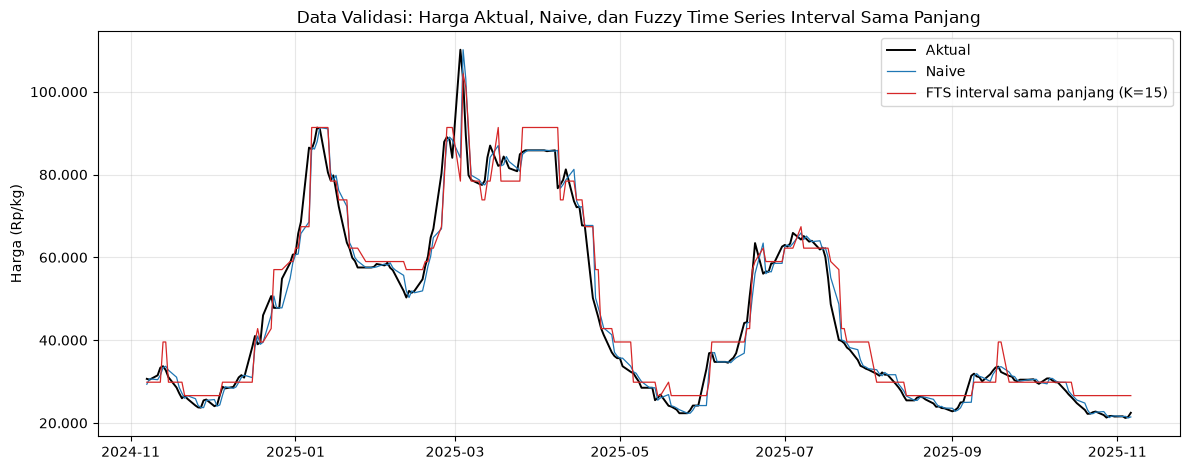

In [6]:
KANDIDAT_K = [5, 7, 10, 15, 20, 30, 40, 60, 80, 100, 150]
RENTANG_RANCANGAN = 20

baris = []
model_fts = {}
for K in KANDIDAT_K:
    batas = interval_sama_panjang(latih, K)
    m = FuzzyTimeSeriesChen(batas).fit(latih)
    pred = pd.Series(m.ramal(acuan_validasi.values), index=validasi.index)
    model_fts[K] = (m, pred)
    baris.append({
        "K": K,
        "lebar_interval": batas[1] - batas[0],
        "himpunan_tanpa_aturan": int((m.jumlah_transisi == 0).sum()),
        "data_per_himpunan_min": int(m.jumlah_data.min()),
        **ringkas_metrik(validasi, pred),
    })
tabel_fts = pd.DataFrame(baris).set_index("K")

K_rancangan = int(tabel_fts.loc[tabel_fts.index <= RENTANG_RANCANGAN, "MAPE_%"].idxmin())
K_semua = int(tabel_fts["MAPE_%"].idxmin())

nama_fts = f"FTS interval sama panjang (K={K_rancangan})"
nama_fts_batas = f"FTS interval sama panjang (K={K_semua}, rujukan)"
for nama, K in ((nama_fts, K_rancangan), (nama_fts_batas, K_semua)):
    prediksi[nama] = model_fts[K][1]
    hasil_validasi[nama] = ringkas_metrik(validasi, prediksi[nama])

print("=" * 62)
print("Fuzzy time series interval sama panjang pada data validasi")
print("=" * 62)
print(tabel_fts.round(2).to_string())
print()
print(f"K terbaik pada rentang rancangan (K <= {RENTANG_RANCANGAN}): K = {K_rancangan}")
print(f"K terbaik pada seluruh kandidat : K = {K_semua} (dipakai sebagai rujukan hor hor)")

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(validasi.index, validasi.values, color="black", linewidth=1.4, label="Aktual")
ax.plot(prediksi["Naive"].index, prediksi["Naive"].values, color="tab:blue", linewidth=0.9, label="Naive")
ax.plot(prediksi[nama_fts].index, prediksi[nama_fts].values, color="tab:red", linewidth=0.9, label=nama_fts)
ax.set_title("Data Validasi: Harga Aktual, Naive, dan Fuzzy Time Series Interval Sama Panjang")
ax.set_ylabel("Harga (Rp/kg)")
ax.yaxis.set_major_formatter(rupiah)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(config.DIR_IMG / "4_validasi_baseline.png", dpi=150)
plt.show()

>INTERPRETASI (Fuzzy Time Series interval sama panjang)
>
>MAPE validasi menurun seiring bertambahnya jumlah interval, tetapi tidak mulus. Pada rentang rancangan (K sampai 20), MAPE adalah 19,40% (K = 5), 12,15% (K = 7), 8,77% (K = 10), 8,51% (K = 15), dan 9,14% (K = 20). Fakta bahwa K = 20 lebih buruk daripada K = 15 menunjukkan bahwa kualitas model tidak hanya ditentukan jumlah interval, tetapi juga letak batasnya. Inilah celah yang dapat dimanfaatkan optimasi batas oleh Algoritma Genetika.
>
>Pada rentang rancangan, model terbaik adalah K = 15 dengan MAPE 8,51%, RMSE Rp 5.049, dan MAE Rp 3.583, atau sekitar 2,2 kali MAPE naive. Lebar interval pada K = 15 adalah Rp 6.477, sehingga meskipun himpunannya selalu terklasifikasi benar, ramalan hanya dapat berupa titik tengah kelompok dengan kesalahan wajar sampai kira-kira setengah lebar interval.
>
>Bila K diperbesar sampai 150, MAPE turun menjadi 4,72% (RMSE Rp 3.756 dan MAE Rp 2.263), tetapi tetap sekitar 1,2 kali MAPE naive, dengan 14 himpunan tanpa aturan dan sebagian himpunan tanpa data latih. Model dengan 150 himpunan juga sulit dijelaskan sebagai himpunan fuzzy yang bermakna. Nilai ini kami pakai hanya sebagai rujukan batas atas.
>
>Grafik memperlihatkan peramalan Fuzzy Time Series (K = 15) berbentuk anak tangga: harga aktual bergerak sementara ramalan mendatar sampai harga melompat ke interval lain. Di beberapa titik ramalan mendatar di atas harga aktual, misalnya sekitar Rp 91.000 pada Maret sampai pertengahan April 2025 saat harga aktual sekitar Rp 86.000, dan sekitar Rp 26.500 pada Oktober sampai awal November 2025 saat harga aktual turun sampai sekitar Rp 21.000 sampai Rp 22.000. Garis naive tampak mengikuti harga aktual dengan keterlambatan satu pencatatan.

#### ****4.3 Catatan untuk Notebook 5****

1. Pembanding langsung bagi Algoritma Genetika adalah Fuzzy Time Series interval sama panjang pada jumlah interval yang sama. Jumlah interval yang dibandingkan adalah 7, 10, 15, dan 20. Perbandingan pada K yang sama diperlukan karena menambah K saja sudah menurunkan kesalahan.
2. Tolok ukur pada rentang rancangan: MAPE validasi 8,51% untuk K = 15. Rujukan batas atas: 4,72% untuk K = 150. Patokan naive: 3,85%.
3. Sasaran yang realistis bagi Algoritma Genetika adalah menurunkan kesalahan pada K kecil mendekati rujukan batas atas, bukan mengalahkan naive. Posisi terhadap naive tetap dilaporkan apa adanya.
4. Hasil K = 15 dan K = 20 yang tidak berurutan menunjukkan letak batas berpengaruh terhadap kesalahan. Hal ini memberi alasan mencoba optimasi, tetapi manfaatnya baru terbukti bila lolos uji pada data validasi dan uji.

### ****5. ARIMA****

#### ****5.1 Mengapa langkah ini penting?****

ARIMA adalah model deret waktu klasik yang lazim dipakai untuk peramalan harga. Model ini melengkapi pembanding dari sisi statistik, sehingga posisi Fuzzy Time Series dapat dinilai terhadap pendekatan yang berbeda dari moving average dan pembelajaran mesin.

#### ****5.2 Yang dilakukan****

Sel berikut:
1. Menjalankan uji ADF pada harga dan selisih pertamanya (data latih). Nilai p kecil (di bawah 0,05) mengarah ke deret yang stasioner.
2. Mencoba orde ARIMA(p, d, q) dengan p dari 0 sampai 3 dan q dari 0 sampai 2, untuk d = 0 (dengan konstanta) dan d = 1. Pada tiap nilai d dipilih orde dengan AIC terkecil pada data latih. AIC tidak dibandingkan antar nilai d karena data yang dimodelkan berbeda, sehingga kedua kandidat dibandingkan lewat MAPE validasi.
3. Meramalkan satu langkah pada data validasi dengan parameter yang tetap (tidak dilatih ulang), memakai harga aktual sebagai masukan tiap hari.
4. Melakukan uji kewajaran: ARIMA(0, 1, 0) adalah jalan acak sehingga hasilnya harus sama dengan naive.

In [9]:
import warnings
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

latih_np = latih.values.astype(float)
semua_np = semua.values.astype(float)

print("=" * 62)
print("Uji stasioneritas ADF (data latih)")
print("=" * 62)
print(f"Harga : p-value = {adfuller(latih_np, result_object=False)[1]:.4f}")
print(f"Selisih pertama : p-value = {adfuller(np.diff(latih_np), result_object=False)[1]:.4g}")
print("p-value kecil (< 0.05) menolak dugaan akar unit, yaitu mengarah ke deret stasioner.")

hasil_fit, baris = {}, []
for d, tren in ((0, "c"), (1, "n")):
    for p in range(4):
        for q in range(3):
            with warnings.catch_warnings(record=True) as catatan:
                warnings.simplefilter("always")
                hasil = ARIMA(latih_np, order=(p, d, q), trend=tren).fit()
            hasil_fit[(p, d, q)] = hasil
            baris.append({"orde": f"({p},{d},{q})", "p": p, "d": d, "q": q,
                          "AIC": hasil.aic, "BIC": hasil.bic, "peringatan": len(catatan)})
tabel_arima = pd.DataFrame(baris).set_index("orde")

print()
print("=" * 62)
print("orde ARIMA pada data latih (urut AIC pada tiap d)")
print("=" * 62)
print(tabel_arima.sort_values(["d", "AIC"])[["d", "AIC", "BIC", "peringatan"]].round(1).to_string())

def ramal_satu_langkah(orde):
    terapan = hasil_fit[orde].apply(semua_np, refit=False)
    return pd.Series(np.asarray(terapan.fittedvalues), index=semua.index).loc[validasi.index]


# Uji kewajaran: ARIMA(0,1,0) harus identik dengan naive
selisih = (ramal_satu_langkah((0, 1, 0)) - prediksi["Naive"]).abs().max()
print()
print(f"Uji kewajaran: selisih maksimum ARIMA(0,1,0) terhadap naive = {selisih:.6f} (harus mendekati 0)")

# Orde terbaik menurut AIC pada tiap d, lalu dibandingkan lewat MAPE validasi
kandidat, baris_val = {}, []
for d in (0, 1):
    sub = tabel_arima[tabel_arima["d"] == d]
    terbaik = sub.loc[sub["AIC"].idxmin()]
    orde = (int(terbaik["p"]), d, int(terbaik["q"]))
    kandidat[orde] = ramal_satu_langkah(orde)
    baris_val.append({"orde": f"ARIMA{orde}", **ringkas_metrik(validasi, kandidat[orde])})

print()
print("=" * 62)
print("ARIMA pada data validasi (orde AIC terbaik pada tiap d)")
print("=" * 62)
tabel_val = pd.DataFrame(baris_val).set_index("orde")
print(tabel_val.round(2).to_string())

orde_arima = min(kandidat, key=lambda o: mape(validasi, kandidat[o]))
nama_arima = f"ARIMA{orde_arima}"
prediksi[nama_arima] = kandidat[orde_arima]
hasil_validasi[nama_arima] = ringkas_metrik(validasi, prediksi[nama_arima])
print()
print(f"Orde ARIMA yang dipakai pada perbandingan: {orde_arima}")

Uji stasioneritas ADF (data latih)
Harga : p-value = 0.0000
Selisih pertama : p-value = 4.52e-14
p-value kecil (< 0.05) menolak dugaan akar unit, yaitu mengarah ke deret stasioner.

orde ARIMA pada data latih (urut AIC pada tiap d)
         d      AIC      BIC  peringatan
orde                                    
(3,0,2)  0  22744.0  22779.8           3
(2,0,1)  0  22770.1  22795.7           0
(2,0,0)  0  22797.7  22818.1           0
(3,0,1)  0  22799.0  22829.6           0
(3,0,0)  0  22799.6  22825.2           0
(1,0,1)  0  22801.3  22821.7           0
(1,0,2)  0  22802.2  22827.7           0
(2,0,2)  0  22807.9  22838.5           2
(1,0,0)  0  22911.4  22926.8           0
(0,0,2)  0  25166.5  25186.9           1
(0,0,1)  0  26268.9  26284.2           1
(0,0,0)  0  35265.7  35275.9           0
(3,1,2)  1  22741.0  22771.6           0
(3,1,1)  1  22741.1  22766.6           0
(2,1,2)  1  22751.4  22776.9           0
(1,1,2)  1  22754.6  22775.0           0
(2,1,1)  1  22758.4  22778.9  

>INTERPRETASI (ARIMA)
>
>Uji ADF pada data latih menolak dugaan adanya akar unit, baik untuk harga (p mendekati nol) maupun untuk selisih pertamanya (p = 4,5 kali 10 pangkat minus 14). Hasil ini mengarah ke deret yang stasioner di sekitar tingkat rata-ratanya dengan siklus naik turun, sehingga tidak ada pilihan tunggal antara d = 0 dan d = 1. Karena itu kedua nilai d dicoba.
>
>Pada d = 0, orde dengan AIC terkecil adalah (3,0,2) dengan AIC 22.744,0, dan pada d = 1 adalah (3,1,2) dengan AIC 22.741,0 (orde (3,1,1) hampir sama, 22.741,1). Model jalan acak (0,1,0) memiliki AIC 22.891,0, yaitu 150 poin lebih besar, sehingga pada data latih ada struktur autoregresi dan rata-rata bergerak yang tidak ditangkap model naive. Orde terbaik pada d = 0 menghasilkan 3 peringatan saat pencocokan. Isi peringatan tidak diperiksa, tetapi kemungkinan terkait ketepatan optimasi, sehingga angka ini dibaca dengan hati-hati. Orde terbaik pada d = 1 tidak menghasilkan peringatan.
>
>Pada data validasi, ARIMA(3,0,2) menghasilkan MAPE 3,77% dan ARIMA(3,1,2) menghasilkan MAPE 3,67% (RMSE Rp 3.529 dan MAE Rp 1.854). ARIMA(3,1,2) dipakai pada perbandingan. Uji kewajaran lolos: ARIMA(0,1,0) menghasilkan ramalan yang identik dengan naive, sehingga cara peramalan satu langkah pada ARIMA sudah sama dengan protokol model lain.

### ****6. Perbandingan Model dan Implikasinya****

#### ****6.1 Mengapa langkah ini penting?****

Seluruh model dasar kini diukur dengan metrik dan protokol yang sama. Perbandingan ini menetapkan tolok ukur yang harus dilampaui Algoritma Genetika, sekaligus menunjukkan seberapa realistis sasaran proyek.

#### ****6.2 Yang dilakukan****

Sel berikut mengumpulkan seluruh hasil validasi dalam satu tabel yang diurutkan menurut MAPE, menghitung selisih tiap model terhadap naive, dan menampilkannya dalam grafik batang. Konfigurasi terpilih (misalnya jendela moving average, lag, dan jumlah interval) beserta tabel hasil disimpan di folder Model agar dapat dipakai pada notebook evaluasi.

Perbandingan seluruh model dasar pada data validasi (urut MAPE)
                                            MAPE_%     RMSE      MAE  selisih_MAPE_vs_naive_(poin)  MAPE_terhadap_naive_(kali)
ARIMA(3, 1, 2)                                3.67  3529.38  1854.04                         -0.17                        0.96
Regresi linear (lag=7)                        3.76  3488.30  1891.66                         -0.09                        0.98
Naive                                         3.85  3628.60  1908.05                          0.00                        1.00
FTS interval sama panjang (K=150, rujukan)    4.72  3755.87  2263.49                          0.87                        1.23
Perceptron berlapis (lag=5, 16 neuron)        4.97  3927.29  2372.49                          1.12                        1.29
Moving average (k=2)                          5.22  4336.31  2559.48                          1.38                        1.36
FTS interval sama panjang (K=15)              8

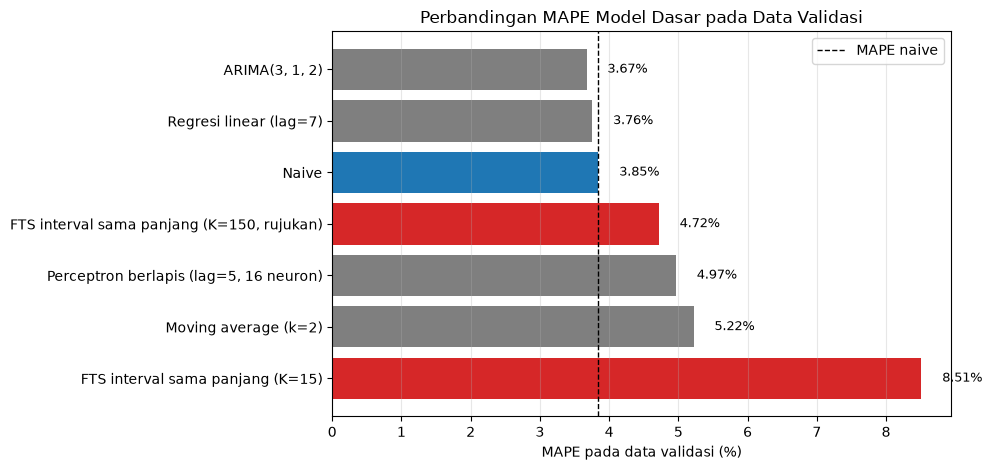


Tersimpan: hasil_baseline_validasi.csv dan konfigurasi_baseline.json di folder Model


In [10]:
import json

perbandingan = pd.DataFrame(hasil_validasi).T
acuan_naive = perbandingan.loc["Naive"]
perbandingan["selisih_MAPE_vs_naive_(poin)"] = perbandingan["MAPE_%"] - acuan_naive["MAPE_%"]
perbandingan["MAPE_terhadap_naive_(kali)"] = perbandingan["MAPE_%"] / acuan_naive["MAPE_%"]
perbandingan = perbandingan.sort_values("MAPE_%")

print("=" * 62)
print("Perbandingan seluruh model dasar pada data validasi (urut MAPE)")
print("=" * 62)
print(perbandingan.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4.8))
urut = perbandingan["MAPE_%"].sort_values(ascending=False)
warna = ["tab:blue" if n == "Naive" else "tab:red" if n.startswith("FTS") else "tab:gray" for n in urut.index]
ax.barh(urut.index, urut.values, color=warna)
ax.axvline(acuan_naive["MAPE_%"], color="black", linestyle="--", linewidth=1, label="MAPE naive")
for i, nilai in enumerate(urut.values):
    ax.text(nilai + 0.3, i, f"{nilai:.2f}%", va="center", fontsize=9)
ax.set_xlabel("MAPE pada data validasi (%)")
ax.set_title("Perbandingan MAPE Model Dasar pada Data Validasi")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(config.DIR_IMG / "4_perbandingan_mape_validasi.png", dpi=150)
plt.show()

perbandingan.to_csv(config.DIR_MODEL / "hasil_baseline_validasi.csv")
konfigurasi = {
    "moving_average_k": int(k_terbaik),
    "regresi_linear_lag": int(L_terbaik),
    "perceptron_lag": int(L_MLP),
    "fts_sama_panjang_K_rancangan": int(K_rancangan),
    "fts_sama_panjang_K_rujukan": int(K_semua),
    "arima_orde": list(orde_arima),
}
with open(config.DIR_MODEL / "konfigurasi_baseline.json", "w", encoding="utf-8") as f:
    json.dump(konfigurasi, f, indent=2, ensure_ascii=False)
print()
print("Tersimpan: hasil_baseline_validasi.csv dan konfigurasi_baseline.json di folder Model")

>INTERPRETASI (Perbandingan model dasar)
>
>Urutan MAPE pada data validasi adalah ARIMA(3,1,2) 3,67%, regresi linear 3,76%, naive 3,85%, Fuzzy Time Series K = 150 (rujukan) 4,72%, perceptron berlapis 4,97%, moving average 5,22%, dan Fuzzy Time Series K = 15 sebesar 8,51%.
>
>Tiga model teratas hampir tidak dapat dibedakan: ARIMA dan regresi linear hanya lebih baik 0,17 dan 0,09 poin persen daripada naive, atau sekitar 4% dan 2% lebih kecil secara relatif. Selisih sekecil itu belum diuji kemaknaannya, sehingga belum dapat dikatakan bahwa keduanya benar-benar mengalahkan naive. Tidak ada satu pun model yang menang jauh atas naive.
>
>Seluruh model lain lebih buruk daripada naive. Fuzzy Time Series pada jumlah interval rancangan (K = 15) memiliki kesalahan sekitar 2,2 kali naive, dan bahkan dengan K = 150 masih sekitar 1,2 kali. Pada grafik batang, kedua batang merah (Fuzzy Time Series) berada di sisi kanan garis naive.

#### ****6.3 Implikasi bagi proyek****

1. Model pembanding yang kuat sudah tersedia: ARIMA(3,1,2), regresi linear, dan naive berada dalam selisih 0,18 poin persen MAPE. Mengalahkan naive secara berarti tidak menjadi sasaran yang realistis bagi Fuzzy Time Series.
2. Klaim proyek dirumuskan sesuai kriteria yang sudah ditetapkan di Notebook 1, yaitu apakah optimasi batas interval menurunkan kesalahan dibanding interval sama panjang pada jumlah interval yang sama. Kedudukan terhadap naive, ARIMA, dan model lain dilaporkan apa adanya.
3. Kesenjangan yang dapat diperkecil adalah antara Fuzzy Time Series interval sama panjang pada K kecil (MAPE 8,51% untuk K = 15) dan rujukan batas atas pada K = 150 (4,72%). Sasaran yang terukur: menurunkan kesalahan pada K kecil sejauh mungkin mendekati rujukan tersebut.
4. Seluruh konfigurasi model dasar (jendela moving average, lag, jumlah interval, dan orde ARIMA) dipilih dengan data validasi dan sudah disimpan, sehingga data uji nanti dipakai dengan konfigurasi yang sudah terkunci. Pada tahap evaluasi, uji statistik untuk selisih antar model, misalnya uji Diebold-Mariano, dapat ditambahkan agar kesimpulan tentang selisih yang kecil tidak berlebihan.

### ****7. Ringkasan dan Langkah Berikutnya****

#### ****7.1 Ringkasan****

1. Fungsi metrik MAPE, RMSE, dan MAE sudah diuji pada contoh yang dihitung dengan tangan, dan seluruh model dinilai dengan protokol peramalan satu langkah yang sama.
2. Pada data validasi, MAPE naive 3,85%, ARIMA(3,1,2) 3,67%, regresi linear (lag 7) 3,76%, Fuzzy Time Series interval sama panjang 8,51% (K = 15) dan 4,72% (K = 150, rujukan), perceptron berlapis 4,97%, dan moving average (k = 2) 5,22%.
3. Model sederhana sangat sulit dikalahkan. Selisih ARIMA dan regresi linear terhadap naive hanya 0,17 dan 0,09 poin persen.
4. Fuzzy Time Series interval sama panjang membaik seiring bertambahnya jumlah interval, tetapi tidak berurutan pada rentang rancangan (K = 20 lebih buruk daripada K = 15). Ini menunjukkan letak batas interval berpengaruh.
5. Aturan Fuzzy Time Series model Chen asli memperlakukan himpunan tujuan yang jarang terjadi sama pentingnya dengan yang sering terjadi, dan titik ramalnya sering berada di tepi interval.

#### ****7.2 Langkah berikutnya****

Pada Notebook 5 kami akan:
1. Menulis modul Algoritma Genetika untuk mengoptimasi batas interval Fuzzy Time Series.
2. Menetapkan kromosom, fungsi kecocokan, operator genetika, dan batasan agar interval tidak menyusut tidak wajar.
3. Menjalankan optimasi untuk K = 7, 10, 15, dan 20 dengan banyak seed.
4. Membandingkan hasilnya dengan Fuzzy Time Series interval sama panjang pada K yang sama pada data validasi.